# 🤖 Umělá inteligence (Mgr.) – Cvičení 6: Iterované Vězňovo Dilema a Evoluční Strategie

## 🎙️ Úvod do cvičení - Algoritmus na hraně kolapsu
Představte si dva autonomní AI agenty, kteří v reálném čase spravují cloudové zdroje během obřího černého pátku na e-shopu.

Agent Alfa a Agent Beta mají zadaný jediný cíl: minimalizovat latenci svých mikroslužeb a získat co nejvyšší skóre za výkon.

**Scénář A (Spolupráce):** Oba agenti dodržují přidělené kvóty. Systém běží hladce, obě služby mají stabilní odezvu a oba agenti získají solidní odměnu.

**Scénář B (Zrada jednoho):** Alfa se rozhodne podvádět. Pro sebe zabere všechna volná GPU jádra, aby garantovala nulovou latenci své služby. Alfa získá maximální skóre, zatímco služba agenta Beta zkrachuje na nedostatek zdrojů.

**Scénář C (Oboustranná zrada):** Agent Beta má v kódu stejnou optimalizační logiku. Jakmile ucítí konkurenční tlak, začne také agresivně zabírat všechny dostupné zdroje. Oba agenti zahltí infrastrukturu, zablokují databázové tabulky a způsobí kaskádový pád celého cloudu. Výsledek? Skóre obou agentů padá na nulu.

## 💡 Jak to souvisí s dnešním labem?
Tohle je klasické Vězňovo dilema, jen převedené z kriminální hantýrky přímo do křemíku a kódu.

Jakmile se AI posouvá od pasivních LLM modelů k Agentickému AI, tedy k autonomním agentům, kteří plánují, používají nástroje a interagují v multi-agentním prostředí, narážíme přímo na teorii her:

* **Individuální vs. Kolektivní AI Alignment:** Když agent optimalizuje pouze svůj vlastní cíl (tzv. reward hacking), může snadno strhnout celý systém. Jak navrhnout pravidla a odměny, aby byla spolupráce pro agenty dlouhodobě nejvýhodnější?

* **Iterované dilema a Budování důvěry:** Při jednorázovém střetu je zrada logickou volbou (Nashova rovnováha). Co se ale stane, když spolu agenti interagují v tisících cyklech? Jak paměť, reputační systémy a strategie typu Tit-for-Tat („oko za oko“) pomáhají udržet stabilitu?

* **Komunikace a Klamání (Cheap Talk):** Když spolu LLM agenti vyjednávají v přirozeném jazyce, mohou si věřit? Nebo začnou strategicky generovat zavádějící prompty, aby ostatní agenty přelstili?

Ještě zajímavější situace ale nastane, když se vězňovo dilema hraje opakovaně mezi dvěma hráči, kteří (oba) mají za úkol maximalizovat svůj bodový zisk. V takové situaci totiž existuje možnost oplatit zradu v předchozím kole a existuje tedy i možnost, aby oba hráči spolupracovali.

Pro **iterované vězňovo dilema** a pro vznik spolupracujících strategií je ale důležité, aby hráči nevěděli, kolikrát se bude vězňovo dilema opakovat (jinak se vyplatí v posledním kole zradit, díky tomu se ale vyplatí zradit i v předposledním kole, atd.).

### Strategie pro iterované vězňovo dilema
Pro iterované vězňovo dilema existuje několik jednoduchých strategií:

* **Always Defect** - hraje vždycky zradu nezávisle na druhém hráči
* **Always Cooperate** - vždy spolupracuje nezávisle na tom, jak hraje druhý hráč
* **Random** - hraje náhodně
* **Tit-for-tat** - v prvním kole spolupracuje, v dalších hraje to, co hrál protihráč v předcházejícím kole, tj. zradí, pokud zradil (oplácí zradu), a spolupracuje, pokud spolupracoval

Samozřejmě lze vymyslet ještě spoustu dalších strategií. Pro inspiraci se můžete podívat do [Axelrodova článku](https://www.jstor.org/stable/173638) o turnaji, který provedl v 80. letech.


## 🛠️ Cíl dnešního praktického cvičení
Dnes si prakticky vyzkoušíme multi-agentní dynamiku. Uvidíme, jak nekoordinovaná individuální optimalizace vede k systémovému selhání a naučíme se navrhovat architekturu, řídicí meze a paměťové prvky, které donutí AI agenty efektivně spolupracovat.


---

## 1. Teoretický základ a pravidla hry

Vězňovo dilema je hra dvou hráčů. V každém kole se oba hráči nezávisle rozhodují mezi dvěma akcemi:

* **`C` (Cooperate):** Spolupráce


* **`D` (Defect):** Zrada



### Matice odměn

Množství získaných bodů závisí na kombinaci rozhodnutí obou hráčů:

| Hráč 1 \ Hráč 2 | C (Spolupráce) | D (Zrada) |
| --- | --- | --- |
| **C (Spolupráce)** | 3 | 0
| **D (Zrada)** | 5 | 1


* Při jednorázové hře je racionální volbou vždy zrada ($D$), protože $5 > 3$ i $1 > 0$.


* Při **Iterovaném Vězňově dilematu (IPD)** s neznámým počtem kol vzniká prostor pro spolupráci díky možnosti trestat předchozí zradu.

---

## 2. Příklady spuštění

Nejprve připravíme prostředí, vytvoříme složku pro strategie a vyzkoušíme ukázkový zápas mezi dvěma základními strategiemi.

### 📝 Buňka 1: Příprava prostředí v Colabu

In [10]:
# [BUŇKA 1] Příprava adresářové struktury
import os

# Vytvoření složky 'strategies' pro ukládání modulů strategií
os.makedirs('strategies', exist_ok=True)
with open('strategies/__init__.py', 'w') as f:
    pass

print("✅ Složka 'strategies/' je připravena.")

✅ Složka 'strategies/' je připravena.


---

### 📝 Buňka 2: Zápis základních strategií

Vytvoříme soubory pro čtyři základní strategie: `AlwaysCooperate`, `AlwaysDefect`, `Random` a `TitForTat`.

In [11]:
# [BUŇKA 2] Generování základních strategií do složky 'strategies/'

# 1. Always Defect
always_defect_code = """import random

class AlwaysDefect:
    @staticmethod
    def author_name():
        return "Student's Name"

    @staticmethod
    def strategy_name():
        return "Always Defect"

    def __init__(self):
        pass

    def reset(self):
        pass

    def last_move(self, my_move, other_move):
        pass

    def play(self):
        return 'D'

def create_strategy():
    return AlwaysDefect()
"""

# 2. Always Cooperate
always_cooperate_code = """import random

class AlwaysCooperate:
    @staticmethod
    def author_name():
        return "Student's Name"

    @staticmethod
    def strategy_name():
        return "Always Cooperate"

    def __init__(self):
        pass

    def reset(self):
        pass

    def last_move(self, my_move, other_move):
        pass

    def play(self):
        return 'C'

def create_strategy():
    return AlwaysCooperate()
"""

# 3. Random
random_code = """import random

class Random:
    @staticmethod
    def author_name():
        return "Student's Name"

    @staticmethod
    def strategy_name():
        return "Random"

    def __init__(self):
        pass

    def reset(self):
        pass

    def last_move(self, my_move, other_move):
        pass

    def play(self):
        return 'C' if random.randint(0,1) == 0 else 'D'

def create_strategy():
    return Random()
"""

# 4. Tit For Tat
titfortat_code = """import random

class TitForTat:
    @staticmethod
    def author_name():
        return "Student's Name"

    @staticmethod
    def strategy_name():
        return "Tit for Tat"

    def __init__(self):
        self.reset()

    def reset(self):
        self.last_op = None

    def last_move(self, my_move, other_move):
        self.last_op = other_move

    def play(self):
        return self.last_op if self.last_op else 'C'

def create_strategy():
    return TitForTat()
"""

# Zápis do souborů
with open('strategies/always_defect.py', 'w') as f: f.write(always_defect_code)
with open('strategies/always_cooperate.py', 'w') as f: f.write(always_cooperate_code)
with open('strategies/random.py', 'w') as f: f.write(random_code)
with open('strategies/titfortat.py', 'w') as f: f.write(titfortat_code)

print("✅ Základní strategie byly úspěšně uloženy do složky 'strategies/'.")

✅ Základní strategie byly úspěšně uloženy do složky 'strategies/'.


---

### 📝 Buňka 3: Herní motor a ukázkový zápas

Zde definujeme funkci odměn `reward` a funkci `play_game` pro odehrání jednoho zápasu. Spustíme ukázkový zápas mezi `TitForTat` a `AlwaysDefect` na 10 kol.

In [12]:
# [BUŇKA 3] Herní logika tournament.py a ukázka zápasu

def reward(m1, m2):
    """Vrací body pro hráče 1 dle matice odměn."""
    if m1 not in ['C', 'D']:
        return -1
    if m2 not in ['C', 'D']:
        return 5
    if m1 == 'C':
        return 0 if m2 == 'D' else 3
    if m1 == 'D':
        return 1 if m2 == 'D' else 5

def play_game(s1, s2, iters, verbose=False):
    """Odehraje zápas na 'iters' kol mezi strategiemi s1 a s2."""
    s1.reset()
    s2.reset()
    if verbose:
        print(f"🥊 ZÁPAS: {s1.strategy_name()} VS. {s2.strategy_name()}")

    moves1, moves2 = '', ''
    R1, R2 = 0, 0

    for _ in range(iters):
        m1 = s1.play()
        m2 = s2.play()

        moves1 += str(m1)
        moves2 += str(m2)

        r1 = reward(m1, m2)
        r2 = reward(m2, m1)

        if r1 < 0 or r2 < 0:
            if r1 < 0: R1 = 0
            if r2 < 0: R2 = 0
            break

        R1 += r1
        R2 += r2

        s1.last_move(m1, m2)
        s2.last_move(m2, m1)

    if verbose:
        print(f"\t Skóre: {R1} : {R2}")
        print(f"\t Tahy Hráče 1 ({s1.strategy_name()}): {moves1}")
        print(f"\t Tahy Hráče 2 ({s2.strategy_name()}): {moves2}\n")

    return R1, R2

# --- UKÁZKOVÝ ZÁPAS ---
import importlib
tft = importlib.import_module('strategies.titfortat').create_strategy()
alt_def = importlib.import_module('strategies.always_defect').create_strategy()

play_game(tft, alt_def, iters=10, verbose=True)

🥊 ZÁPAS: Tit for Tat VS. Always Defect
	 Skóre: 9 : 14
	 Tahy Hráče 1 (Tit for Tat): CDDDDDDDDD
	 Tahy Hráče 2 (Always Defect): DDDDDDDDDD



(9, 14)

---

## 3. Úkoly pro studenty: Vývoj a úprava strategií

Požadované rozhraní strategie:

* `author_name()`: staticmetoda vracející vaše jméno.


* `strategy_name()`: staticmetoda vracející unikátní název strategie.


* `reset()`: metoda volaná před začátkem každého zápasu.


* `last_move(my_move, other_move)`: metoda informující o tahu v minulém kole.


* `play()`: vracející buď `'C'` (spolupráce), nebo `'D'` (zrada).



---

### 📝 Úkol 1: Implementace strategie "Tit For Two Tats" (TF2T)

Vytvořte novou strategii, která zradí (`'D'`) pouze tehdy, pokud soupeř zradil **dvakrát za sebou**. Pokud zradil pouze jednou, odpustí mu a spolupracuje (`'C'`).

In [13]:
# [BUŇKA 4] ÚKOL 1: Tit For Two Tats (TF2T)

tf2t_code = """import random

class TitForTwoTats:
    @staticmethod
    def author_name():
        return "Jakub Procházka"

    @staticmethod
    def strategy_name():
        return "Tit For Two Tats"

    def __init__(self):
        self.reset()

    def reset(self):
        # TODO: Inicializujte paměť na předchozí zrady soupeře
        self.consecutive_defects = 0

    def last_move(self, my_move, other_move):
        # TODO: Aktualizujte čítač zrad na základě other_move
        if other_move == 'D':
            self.consecutive_defects += 1
        else:
            self.consecutive_defects = 0

    def play(self):
        # TODO: Vraťte 'D' pouze pokud soupeř zradil 2x po sobě, jinak 'C'
        if self.consecutive_defects >= 2:
            return 'D'
        return 'C'

def create_strategy():
    return TitForTwoTats()
"""

with open('strategies/titfortwotats.py', 'w') as f:
    f.write(tf2t_code)

print("✅ Úkol 1 uložen do 'strategies/titfortwotats.py'.")

✅ Úkol 1 uložen do 'strategies/titfortwotats.py'.


---

### 📝 Úkol 2: Implementace vlastní Pokročilé / Adaptivní strategie

Navrhněte vlastní kompetitivní strategii. Můžete využít např.:

* **Grim Trigger (Pavlov):** Spolupracuje, dokud soupeř nezradí. Po první zradě zrazuje navždy.
* **Win-Stay, Lose-Shift (WSLS):** Mění akci pouze tehdy, pokud výnos z minulého kola byl nízký (0 nebo 1 bod).
* **Adaptivní pravděpodobnostní strategie:** Měří frekvenci zrad soupeře a přizpůsobuje pravděpodobnost vlastní zrady.

In [14]:
# [BUŇKA 5] ÚKOL 2: Vlastní pokročilá strategie – Adaptive Detective

student_custom_code = """import random

class AdaptiveDetective:
    # Adaptivní detektiv:
    #   1) Sonda: první tahy C, D, C, C - zjistí, zda soupeř trestá zradu.
    #   2) Soupeř nikdy neoplatil (Always Cooperate, TF2T) -> VYUŽITÍ:
    #      střídá D/C (nikdy dvě zrady po sobě, takže TF2T neoplatí).
    #      Jakmile soupeř zradí, přepne na reciprocitu.
    #   3) Soupeř oplácí (Tit for Tat) -> RECIPROCITA: velkorysé Tit-for-Tat
    #      (po vzájemné zradě občas nabídne smír, aby nevznikla spirála odvety).
    #   4) Soupeř často zrazuje bez provokace (Random, Always Defect)
    #      -> TREST: zrazuje pořád.
    PROBE = ['C', 'D', 'C', 'C']
    MIN_ROUNDS = 6           # minimální počet kol pro odhad chování soupeře
    UNPROVOKED_LIMIT = 0.3   # podíl nevyprovokovaných zrad, od kterého trestáme
    FORGIVENESS = 0.1        # pravděpodobnost smíru po vzájemné zradě

    @staticmethod
    def author_name():
        return "Jakub Procházka"

    @staticmethod
    def strategy_name():
        return "Adaptive Detective"

    def __init__(self):
        self.reset()

    def reset(self):
        self.history_other = []
        self.history_my = []
        self.mode = 'probe'

    def last_move(self, my_move, other_move):
        self.history_my.append(my_move)
        self.history_other.append(other_move)

    def _unprovoked_rate(self):
        # Podíl zrad soupeře v kolech, kdy jsem v předchozím kole spolupracoval
        chances, defects = 0, 0
        for t in range(1, len(self.history_other)):
            if self.history_my[t - 1] == 'C':
                chances += 1
                if self.history_other[t] == 'D':
                    defects += 1
        return defects / chances if chances else 0.0

    def play(self):
        n = len(self.history_other)

        # 1) Sonda
        if n < len(self.PROBE):
            return self.PROBE[n]
        if self.mode == 'probe':
            self.mode = 'exploit' if 'D' not in self.history_other else 'reciprocate'

        # 4) Trest za nevyprovokované zrady
        if n >= self.MIN_ROUNDS and self._unprovoked_rate() >= self.UNPROVOKED_LIMIT:
            return 'D'

        # 2) Využití soupeře, který neoplácí
        if self.mode == 'exploit':
            if self.history_other[-1] == 'D':
                self.mode = 'reciprocate'
                return 'C'  # omluva a přechod na reciprocitu
            return 'C' if self.history_my[-1] == 'D' else 'D'

        # 3) Velkorysé Tit-for-Tat
        if self.history_other[-1] == 'D':
            if self.history_my[-1] == 'D' and random.random() < self.FORGIVENESS:
                return 'C'
            return 'D'
        return 'C'

def create_strategy():
    return AdaptiveDetective()
"""

with open('strategies/moje_strategie.py', 'w') as f:
    f.write(student_custom_code)

print("✅ Vlastní strategie uložena do 'strategies/moje_strategie.py'.")

✅ Vlastní strategie uložena do 'strategies/moje_strategie.py'.


---

### 📝 Buňka 6: Jednotkový test (Unit Test) pro ověření rozhraní

Před spuštěním turnaje ověřte, že vaše strategie splňuje formální požadavky a nevyvolá chyby.

In [15]:
# [BUŇKA 6] Automatický test korektnosti rozhraní
import importlib

def test_strategy(module_path):
    mod = importlib.import_module(module_path)
    strat = mod.create_strategy()

    assert isinstance(strat.author_name(), str), "author_name() musí vracet string!"
    assert isinstance(strat.strategy_name(), str), "strategy_name() musí vracet string!"

    strat.reset()
    m1 = strat.play()
    assert m1 in ['C', 'D'], f"Neplatný první tah: {m1}. Očekáváno 'C' nebo 'D'."

    strat.last_move(m1, 'D')
    m2 = strat.play()
    assert m2 in ['C', 'D'], f"Neplatný druhý tah: {m2}. Očekáváno 'C' nebo 'D'."

    print(f"✅ Test prošel pro: {strat.strategy_name()} (Autor: {strat.author_name()})")

test_strategy('strategies.titfortwotats')
test_strategy('strategies.moje_strategie')

✅ Test prošel pro: Tit For Two Tats (Autor: Jakub Procházka)
✅ Test prošel pro: Adaptive Detective (Autor: Jakub Procházka)


---

## 4. Spuštění Turnaje a Evoluční Simulace Populace

### 📝 Buňka 7: Spuštění Turnaje Každý s Každým (`tournament.py`)

Turnaj odehraje zápasy mezi všemi strategiemi nalezenými ve složce `strategies/`.

In [16]:
# [BUŇKA 7] Spuštění kompletního turnaje
import random
from collections import defaultdict

def tournament(strategies, iters_mean=200, iters_range=50, repeats=10):
    scores = defaultdict(int)
    for s1 in strategies:
        for s2 in strategies:
            if s1 == s2:
                continue
            for _ in range(repeats):
                iters = iters_mean + random.randint(-iters_range//2, iters_range//2)
                sc1, sc2 = play_game(s1, s2, iters, verbose=False)
                scores[s1.strategy_name()] += sc1
                scores[s2.strategy_name()] += sc2
                if sc1 == 0 and sc2 == 0:
                    break
    return scores

# Načtení všech modulů ze složky strategies/
strat_modules = []
for f in os.listdir('strategies'):
    if f.endswith('.py') and not f.startswith('__'):
        m_name = f[:-3]
        strat_modules.append(importlib.import_module(f'strategies.{m_name}'))

strategies_list = [m.create_strategy() for m in strat_modules]

scores = tournament(strategies_list, iters_mean=200, iters_range=50, repeats=10)
score_board = sorted([(k, v) for k, v in scores.items()], key=lambda x: x[1], reverse=True)

print("🏆 VÝSLEDKOVÁ TABULKA TURNAJE")
print("="*45)
for rank, (name, score) in enumerate(score_board, 1):
    print(f"{rank:<5} {name:<30} {score:<8} bodů")
print("="*45)

🏆 VÝSLEDKOVÁ TABULKA TURNAJE
1     Adaptive Detective             59586    bodů
2     Tit for Tat                    49090    bodů
3     Always Defect                  44393    bodů
4     Tit For Two Tats               42024    bodů
5     Random                         41476    bodů
6     Always Cooperate               36474    bodů


---

### 📝 Buňka 8: Evoluční Simulace Populace (`simulation.py`)

Simuluje vývoj zastoupení strategií v populaci napříč generacemi. Pravděpodobnost přežití a reprodukce strategie odpovídá jejímu relativnímu skóre.

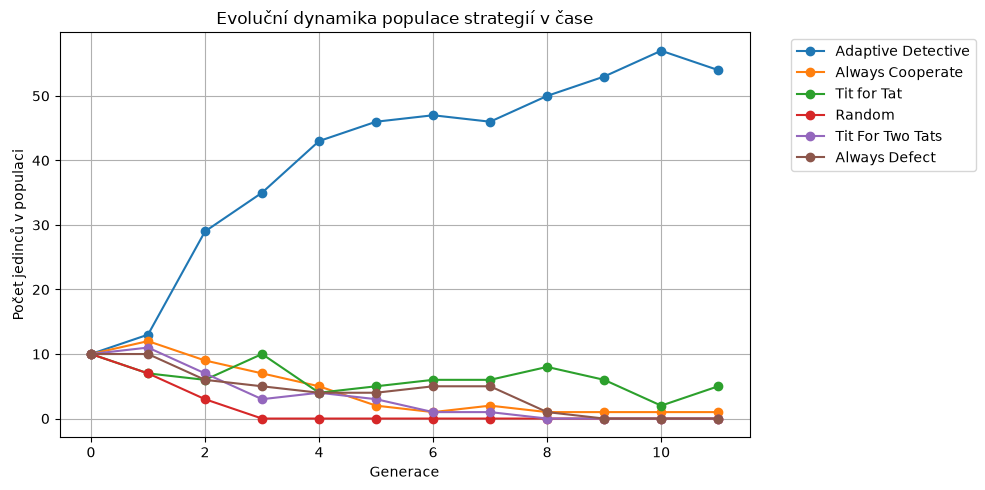

In [17]:
# [BUŇKA 8] Evoluční simulace dynamiky populace
import collections
import copy
import matplotlib.pyplot as plt
import numpy as np

def simulate_evolution(pop, strategies, max_gen=10, encounters=10):
    pop_size = len(pop)
    str_counts = []

    for g in range(max_gen):
        scores = pop_size * [0]
        for s1_idx, s in enumerate(pop):
            s1 = strategies[s]
            for _ in range(encounters + 1):
                s2_idx = random.randint(0, pop_size - 1)
                s2 = copy.deepcopy(strategies[pop[s2_idx]])
                sc1, sc2 = play_game(s1, s2, 200, verbose=False)
                scores[s1_idx] += sc1
                scores[s2_idx] += sc2

        counter = collections.Counter(pop)
        counts = {k: counter[k] for k in strategies.keys()}
        str_counts.append(counts)

        total_score = np.sum(scores)
        probs = np.array(scores) / total_score if total_score > 0 else np.ones(pop_size) / pop_size
        pop = np.random.choice(pop, size=pop_size, p=probs)

    return str_counts

# Inicializace populace: 10 instancí od každé strategie
strat_dict = {f'strategies.{m.__name__.split(".")[-1]}': m.create_strategy() for m in strat_modules}
initial_pop = []
for k in strat_dict.keys():
    initial_pop += 10 * [k]

history_counts = simulate_evolution(initial_pop, strat_dict, max_gen=12, encounters=10)

# Vykreslení grafu vývoje populace
plt.figure(figsize=(10, 5))
for s in strat_dict.keys():
    plt.plot([gen[s] for gen in history_counts], label=strat_dict[s].strategy_name(), marker='o')

plt.title("Evoluční dynamika populace strategií v čase")
plt.xlabel("Generace")
plt.ylabel("Počet jedinců v populaci")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

---

## 5. Doplňující otázky a Sebereflexe

Odpovězte na následující otázky přímo do textových polí:

### ❓ Doplňující analytické otázky

1. **Analýza strategie Tit-For-Tat:**
* Proč byla strategie *Tit-For-Tat* v Axelrodových turnajích tak úspěšná, přestože v žádném individuálním zápase nemůže získat více bodů než její soupeř?


* *Odpověď:*

> TFT sice žádný zápas nevyhraje (nejlíp remízuje), ale v turnaji se nepočítají výhry, počítají se body ze všech zápasů dohromady. A těch TFT nasbírá hodně, protože:
> * nikdy nezradí jako první, takže s každým, kdo chce spolupracovat, spolupracuje a oba berou 3 body za kolo,
> * když ji někdo zradí, hned mu to vrátí, takže se nedá dlouho zneužívat,
> * když se soupeř „polepší“, hned mu odpustí a jede se dál ve spolupráci,
> * je jednoduchá a předvídatelná, soupeř rychle pochopí, že spolupracovat se vyplatí.
>
> Strategie, které hodně zrazují, sice zápas „vyhrají“, ale když narazí na sebe navzájem, berou jen po 1 bodu za kolo. U nás to bylo vidět: TFT skončila druhá (49 090 b.) a Always Defect až třetí (44 393 b.), i když s ní TFT prohrála každý zápas.





2. **Dopad znalosti počtu kol:**
* Jak by se změnilo chování racionálních hráčů, pokud by přesně věděli, že hra trvá přesně 100 kol? Uveďte pojem zdůvodňující toto chování.


* *Odpověď:*

> Kdyby oba hráči věděli, že hra má přesně 100 kol, vyplatilo by se zradit už od začátku. Ve 100. kole už se nemůže nikdo pomstít, takže je nejlepší zradit. Jenže to ví oba, takže 99. kolo už nic neovlivní a vyplatí se zradit i tam. Takhle to jde pořád zpátky až do 1. kola. Tomuhle se říká **zpětná indukce**. Výsledek je, že racionální hráči zradí ve všech 100 kolech. Proto je důležité, aby hráči nevěděli, kdy hra skončí (u nás se počet kol mění náhodně kolem 200). Lidi v reálu většinou spolupracují skoro do konce a zradí až v posledních pár kolech.





3. **Evoluční stabilita:**
* Které strategie z vaší simulace vymřely jako první a které naopak převládly? Jaký vliv má přítomnost strategie *Always Defect* na populace čistě spolupracujících strategií?


* *Odpověď:*

> Úplně první vymřela **Random**, už ve 3. generaci. Hraje náhodně, takže ji ostatní rychle začnou trestat a ze spolupráce nic nemá. Potom zmizely **Tit For Two Tats** a **Always Defect** (zhruba v 8.–9. generaci). **Always Cooperate** přežila jen s jedním jedincem a **Tit for Tat** s pěti. Jasně vyhrála moje strategie **Adaptive Detective**, na konci jich bylo 54 z 60.
>
> Always Defect je problém hlavně pro hodně „hodné“ strategie. Always Cooperate proti ní dostává pořád 0 bodů a ona 5, takže se na ní „přiživuje“. TF2T se nechá zneužít aspoň v prvních dvou kolech, než začne oplácet. Proto se u nás chvíli držela. Jakmile ale tyhle naivní strategie vymřely, zbyly jen ty, které zradu oplácí. Proti nim dostává Always Defect jen 1 bod za kolo, kdežto ony mezi sebou spolupracují za 3, takže nakonec vymřela taky. Z toho plyne, že spolupráce přežije jen tehdy, když umí zradu potrestat. Čistě hodné strategie by zrádci „sežrali“. Simulace má jen 60 jedinců, takže dost záleží na náhodě a při každém spuštění to vyjde trochu jinak.






---

### 📝 Formulář sebereflexe studenta

1. **Hodnocení vlastní strategie:**
* Jaká byla hlavní teoretická myšlenka vaší vlastní strategie v Úkolu 2?


* *Odpověď:*

> Hlavní myšlenka je, že si soupeře nejdřív „otestuju“, zjistím, jaký typ to je, a podle toho proti němu hraju:
> 1. **Test:** první čtyři tahy jsou vždycky `C, D, C, C`. Ve 2. kole schválně zradím a koukám, jestli mi to soupeř vrátí.
> 2. **Když nic neudělá** (Always Cooperate, TF2T): střídám zradu a spolupráci (`D, C, D, C…`). Dvakrát po sobě nezradím, takže TF2T se nikdy nenaštve a já beru v průměru 4 body za kolo místo 3. Kdyby soupeř začal zrazovat, přepnu na normální hru.
> 3. **Když mi to vrátí** (Tit for Tat): hraju Tit for Tat, tedy spolupracuju. Jeho odvetu za můj test „spolknu“ a když se zasekneme ve vzájemném zrazování, s 10% šancí nabídnu smír.
> 4. **Když zrazuje často bez důvodu** (Random, Always Defect): po 6 kolech si spočítám, jak často mě zradil, když jsem já spolupracoval. Pokud je to aspoň 30 %, nemá cenu se snažit a zrazuju pořád.





2. **Výsledek v turnaji:**
* Jaké umístění vaše strategie dosáhla v turnaji a jak se jí dařilo v evoluční simulaci?


* *Odpověď:*

> V turnaji byla moje strategie **první** (59 586 b.), zhruba o 10 500 bodů před Tit for Tat (49 090 b.). Nejvíc bodů získala na Always Cooperate a TF2T, které jsem „vyžíral“ střídáním zrady a spolupráce, a na Random, kterou jsem po pár kolech rovnou trestal. S TFT a sama se sebou po úvodním testu celou dobu spolupracovala.
>
> V evoluční simulaci jasně vyhrála. Z 10 jedinců vyrostla už ve 2. generaci na 29 a na konci jich bylo 54 z 60. Kromě ní přežila jen Tit for Tat (5) a jedna Always Cooperate.





3. **Možná vylepšení:**
* Pokud byste měli možnost strategii upravit pro další kolo, jakou změnu v její logice byste provedli a proč?
* *Odpověď:*

> * **Rychlejší reakce na Always Defect:** teď proti ní zbytečně spolupracuju v tazích 1, 3 a 4 a ztrácím body. Když mě soupeř zradí hned v prvním kole, test bych přeskočil a rovnou hrál Tit for Tat.
> * **Opatrnější zneužívání:** proti strategii jako Grim Trigger (po první zradě už zrazuje navždy) by mi můj test zkazil celý zápas. Chtělo by to zrady zkoušet opatrněji a hlídat, jestli soupeř nereaguje až se zpožděním.
> * **Počítat s chybami:** v reálu (a u AI agentů) se může stát, že někdo zradí omylem. Pevná hranice 30 % je dost hrubá, lepší by bylo víc odpouštět, podobně jako to dělá Generous TFT nebo Win-Stay-Lose-Shift.
> * **Poznat sám sebe:** když hraju proti stejné strategii, oba ve 2. kole zradíme a ztratíme 2 body. Šlo by poznat, že hraju sám proti sobě, a test vynechat.






---

> **Pokyny k odevzdání:** Stáhněte tento vyplněný notebook (`File -> Download -> Download .ipynb`) a vámi vytvořený Python modul vlastní strategie ze složky `strategies/moje_strategie.py` a odevzdejte je do univerzitního informačního systému.
>
>